# Simulated Data

In [1]:
from STalign import STalign
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import plotly
import requests
import scanpy as sc
import matplotlib

import warnings
warnings.filterwarnings("ignore")

## Load Data

In [ ]:
file_path = './simData-20241219T155123Z-001/simData/DLPFC_151673_overlap=100__pseudocount_0_spotIndex.h5'

ad_ = sc.read_h5ad(file_path)


In [6]:
print(ad_)

AnnData object with n_obs × n_vars = 3596 × 33538
    obs: 'in_tissue', 'array_row', 'array_col', 'original_clusters', 'SpotIndex'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'


In [40]:
# print(ad_.X)             # Gene expression matrix
print(ad_.obs['original_clusters'])  # Spatial coordinates


AAACAAGTATCTCCCA-1    3
AAACAATCTACTAGCA-1    1
AAACACCAATAACTGC-1    0
AAACAGAGCGACTCCT-1    3
AAACAGCTTTCAGAAG-1    5
                     ..
TTGTTGTGTGTCAAGA-1    5
TTGTTTCACATCCAGG-1    0
TTGTTTCATTAGTCTA-1    0
TTGTTTCCATACAACT-1    6
TTGTTTGTGTAAATTC-1    2
Name: original_clusters, Length: 3596, dtype: category
Categories (7, object): ['0', '1', '2', '3', '4', '5', '6']


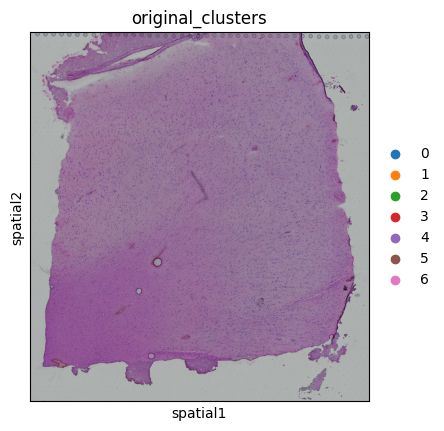

In [14]:
sc.pl.spatial(ad_, color='original_clusters', spot_size=1.5)

In [31]:
file_path = './simData-20241219T155123Z-001/simData/DLPFC_151673original_spotIndex.h5'

ad_target = sc.read_h5ad(file_path)


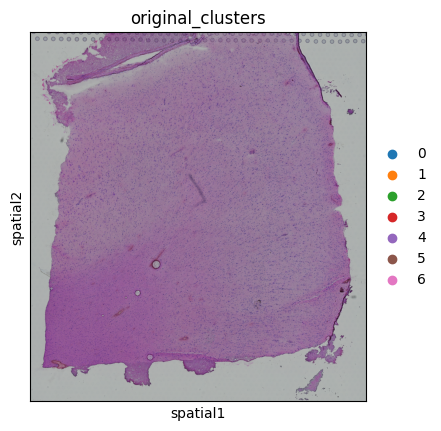

In [32]:
sc.pl.spatial(ad_target, color='original_clusters', spot_size=1.5)

0 of 3611
3610 of 3611


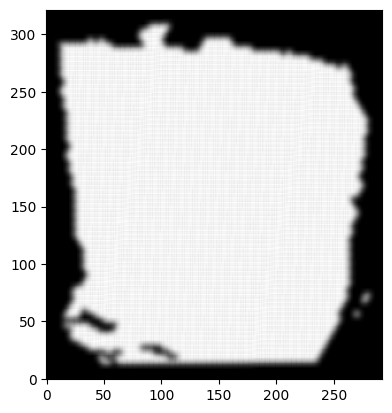

In [33]:
spatial_coords_target = ad_target.obsm['spatial']
x_target = spatial_coords_target[:, 0]
y_target = spatial_coords_target[:, 1]

# fig,ax = plt.subplots()

# rasterize at 30um resolution (assuming positions are in um units) and plot
XJ,YJ,J,fig = STalign.rasterize(x_target,y_target,dx=30,blur=1.5)

# plot
ax = fig.axes[0]
ax.invert_yaxis()

0 of 3596
3595 of 3596


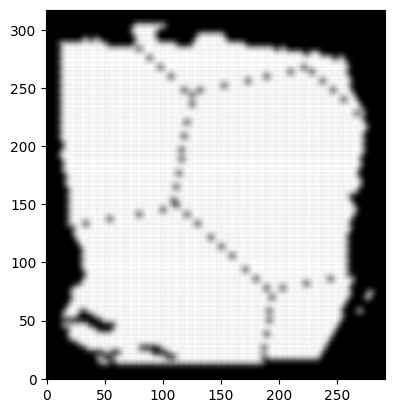

In [34]:
spatial_coords = ad_.obsm['spatial']
x = spatial_coords[:, 0]
y = spatial_coords[:, 1]

# fig,ax = plt.subplots()

# rasterize at 30um resolution (assuming positions are in um units) and plot
XI,YI,I,fig = STalign.rasterize(x,y,dx=30,blur=1.5)

# plot
ax = fig.axes[0]
ax.invert_yaxis()

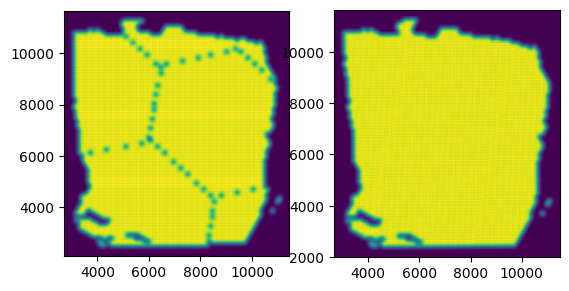

In [35]:
# get extent of images
extentI = STalign.extent_from_x((YI,XI))
extentJ = STalign.extent_from_x((YJ,XJ))

# plot rasterized images
fig,ax = plt.subplots(1,2)
ax[0].imshow(I[0], extent=extentI)
ax[1].imshow(J[0], extent=extentJ)
ax[0].invert_yaxis()
ax[1].invert_yaxis()

c:\Users\Lucif\.conda\envs\st_data\lib\site-packages\STalign\STalign.py:1043: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  L = torch.tensor(L,device=device,dtype=dtype,requires_grad=True)
c:\Users\Lucif\.conda\envs\st_data\lib\site-packages\STalign\STalign.py:1044: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  T = torch.tensor(T,device=device,dtype=dtype,requires_grad=True)
c:\Users\Lucif\.conda\envs\st_data\lib\site-packages\STalign\STalign.py:1301: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  axE[2].set_yscale('log')


CPU times: total: 3h 8min 11s
Wall time: 42min 24s


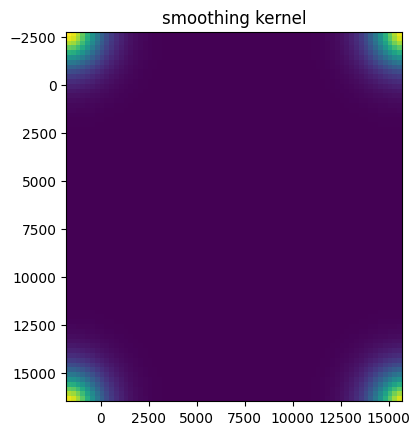

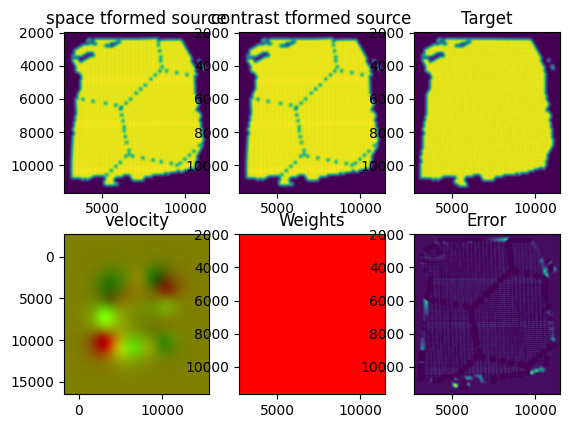

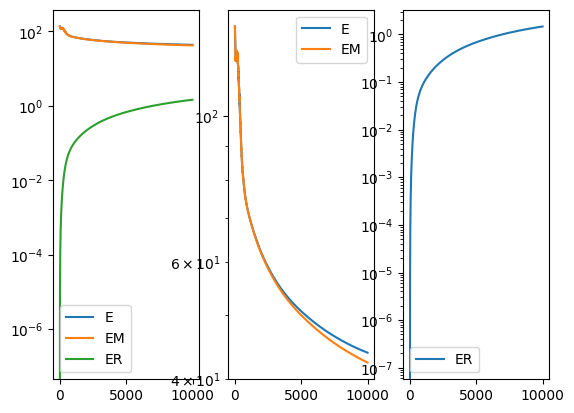

In [ ]:
%%time
# run LDDMM
# specify device (default device for STalign.LDDMM is cpu)
if torch.cuda.is_available():
    device = 'cuda:0'
else:
    device = 'cpu'

# keep all other parameters default
params = {
            'niter': 10000,
            'device':device,
            'epV': 50,
            'sigmaA': 0.1, #standard deviation of artifact intensities
            'sigmaB': 0.1, #standard deviation of background intensities
            'sigmaM': 0.1, #standard deviation of matching tissue intenities
          }

out = STalign.LDDMM([YI,XI],I,[YJ,XJ],J,**params)

In [75]:
# get necessary output variables
A = out['A']
v = out['v']
xv = out['xv']


In [123]:
pointsI = torch.tensor(np.stack([y, x], 1), device='cuda', dtype=torch.float64)

# apply transform to original points
tpointsI= STalign.transform_points_source_to_target(xv,v,A, pointsI)

#switch tensor from cuda to cpu for plotting with numpy
if tpointsI.is_cuda:
    tpointsI = tpointsI.cpu()

#switch from row column coordinates (y,x) to (x,y)
xI_LDDMM = tpointsI[:,1]
yI_LDDMM = tpointsI[:,0]

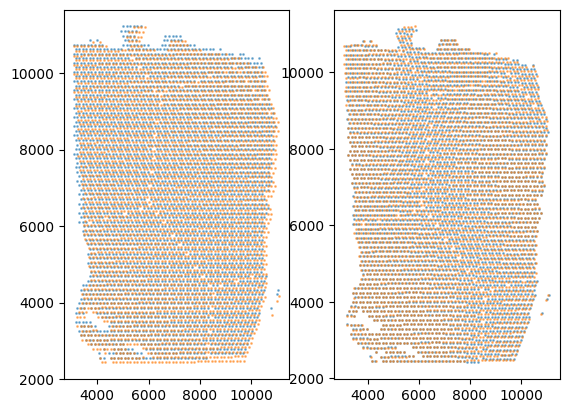

In [124]:
fig,ax = plt.subplots(1,2)
ax[0].scatter(x,y,s=1,alpha=0.5, label='source with initial affine transformation')
ax[0].scatter(x_target,y_target,s=1,alpha=0.5, label='target')
ax[1].scatter(xI_LDDMM,yI_LDDMM,s=1,alpha=0.5, label = 'source STaligned')
ax[1].scatter(x_target,y_target,s=1,alpha=0.5, label='target')
# ax[0].legend(markerscale = 10, loc = 'lower left')
# ax[1].legend(markerscale = 10, loc = 'lower left')

In [78]:
from sklearn.metrics import pairwise

f1 = np.column_stack((x_target, y_target))  # Shape: (n_points, 2)
f2 = np.column_stack((xI_LDDMM, yI_LDDMM))  # Shape: (n_points, 2)
alignment = pairwise.euclidean_distances(f1, f2)
alignment = np.exp(-alignment)

alignment_df = pd.DataFrame(alignment)


In [79]:
# Save as .pkl
alignment_df.to_pickle("151673_100_AlignmentPi.pkl")

## LAA

In [80]:
# LAA
#calculate laywise bar, result needs to be devided by total number to calculate the accuracy rate
def cal_layer_based_alignment_result(alignment, s1, s2):
    #fei added
    labels = []
    labels.extend(s1.obs['original_clusters'])
    labels.extend(s2.obs['original_clusters'])

    res = []
    l_dict = {"0": 0, "1": 1, "2": 2, "3": 3, "4": 4, "5": 5, "6": 6}
    cnt0 = 0
    cnt1 = 0
    cnt2 = 0
    cnt3 = 0
    cnt4 = 0
    cnt5 = 0
    cnt6 = 0
    for i, elem in enumerate(alignment):
        if np.max(elem) - np.min(elem) != 0: # paste2 might have spots that are not aligned to any other spots. paste might have negative alignment
            if labels[i] == '-1' or labels[elem.argmax() + alignment.shape[0]] == '-1':
                continue
            if l_dict[labels[i]] == l_dict[labels[elem.argmax() + alignment.shape[0]]]:
                cnt0 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 1:
                cnt1 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 2:
                cnt2 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 3:
                cnt3 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 4:
                cnt4 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 5:
                cnt5 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 6:
                cnt6 += 1
    res.extend([cnt0, cnt1, cnt2, cnt3, cnt4, cnt5, cnt6])
    return res

In [ ]:
res = cal_layer_based_alignment_result(alignment, ad_, ad_target)
res

[664, 705, 701, 817, 257, 290, 177]

In [87]:
divisor = alignment.shape[0]
LAA_result = [num / divisor for num in res]
print(LAA_result)

[0.18388258100249238, 0.1952367765162005, 0.19412905012461923, 0.22625311548047633, 0.0711714206590972, 0.08031016338964275, 0.04901689282747161]


In [83]:
alignment.shape

(3611, 3596)

## ARI

In [89]:
from sklearn.metrics import adjusted_rand_score


def compute_alignment_ari(sliceA, sliceB, pi):
    mapped_clusters = []
    for j in range(pi.shape[1]):
        mapping = pi[:, j]
        #original: if np.sum(mapping) > 0:
        if np.max(mapping) - np.min(mapping) != 0:
            i = np.argmax(mapping)
            mapped_clusters.append(sliceA.obs['original_clusters'][i])
        else:
            mapped_clusters.append("NULL")
    assert len(sliceB.obs['original_clusters']) == len(mapped_clusters)
    true_clusters_mapped_region = []
    mapped_clusters_mapped_region = []
    for i in range(len(sliceB.obs['original_clusters'])):
        if mapped_clusters[i] != "NULL":
            true_clusters_mapped_region.append(sliceB.obs['original_clusters'][i])
            mapped_clusters_mapped_region.append(mapped_clusters[i])

    ari = adjusted_rand_score(true_clusters_mapped_region, mapped_clusters_mapped_region)
    return ari

In [90]:
ari = compute_alignment_ari(ad_target, ad_, alignment)
ari

0.9836251413182473

## Degree

In [135]:
def get_rotation_angle(R):
    # Extract the sine and cosine from the matrix
    cos_theta = R[0, 0]
    sin_theta = R[1, 0]

    # Compute the angle in radians
    theta = np.arctan2(sin_theta, cos_theta)

    # Convert the angle to degrees (optional)
    theta_deg = np.degrees(theta)

    return theta, theta_deg

In [136]:
# https://github.com/raphael-group/paste/blob/main/src/paste/visualization.py
X = np.array([x_target, y_target]).T
print(X.shape)
Y = np.array([x, y]).T
print(Y.shape)
print(alignment.shape)
tX = alignment.sum(axis=1).dot(X)
tY = alignment.sum(axis=0).dot(Y)
X = X - tX
Y = Y - tY
H = Y.T.dot(alignment.T.dot(X))
U, S, Vt = np.linalg.svd(H)
R = Vt.T.dot(U.T)

theta, theta_deg = get_rotation_angle(R)
theta_deg

(3611, 2)
(3596, 2)
(3611, 3596)


-1.0180808067849163

In [176]:
coordinatesB.shape[0]

739

In [180]:
import ot

coordinatesA = X
# coordinatesA = pd.read_csv('_overlap=100_align.csv')
coordinatesB = pd.read_csv('_overlap=100_align.csv')

# print(coordinatesA)
# print(coordinatesB)

coordinatesA = np.array(coordinatesA)
coordinatesB = np.array(coordinatesB)

disMatrix = ot.dist(coordinatesA, coordinatesB, metric='euclidean')
gt = pd.read_csv('./simData-20241219T155123Z-001/_overlap=100_mapping_matrix_ground_truth_spotIndex.csv', index_col=False)
gt = gt.iloc[:, 1:].reset_index(drop=True)
gt = gt.to_numpy()
s = (gt * disMatrix).sum()
# s
disPerSpot = s / coordinatesB.shape[0]
disPerSpot

155345.63752129365

In [144]:
gt_r_deg = [-1, -10.29, -17.48, -26.47, -38.3]
st_r_deg = [-1.0181, -4.5291, -1.3995, -4.7522, -2.8585]

# Convert to a NumPy array and create DataFrame
r_array = np.array(st_r_deg)[:, np.newaxis] # localOT_deg is the rotation degree of localOT
df = pd.DataFrame(r_array, columns=["localOT_r_deg"])
df['pair'] = range(len(st_r_deg))

# Calculate absolute differences and add as a new column
differences = np.abs(np.array(st_r_deg) - np.array(gt_r_deg))
df['dif_gt'] = differences

df

,localOT_r_deg,pair,dif_gt
0,-1.0181,0,0.0181
1,-4.5291,1,5.7609
2,-1.3995,2,16.0805
3,-4.7522,3,21.7178
4,-2.8585,4,35.4415


## 3D

In [ ]:
dfs = ad_.obs['original_clusters']
df1 = dfs.reset_index()
df1.head()

,index,original_clusters
0,AAACAAGTATCTCCCA-1,3
1,AAACAATCTACTAGCA-1,1
2,AAACACCAATAACTGC-1,0
3,AAACAGAGCGACTCCT-1,3
4,AAACAGCTTTCAGAAG-1,5


In [ ]:
df3_1 = pd.DataFrame(
    {
        "X": xI_LDDMM,
        "Y": yI_LDDMM,
    },
)

results1 = pd.concat([df1, df3_1], axis=1)
results1['Z'] = 1
results1['slice'] = 100
results1

,index,original_clusters,X,Y,Z,slice
0,AAACAAGTATCTCCCA-1,3,9807.196159,8447.111278,1,100
1,AAACAATCTACTAGCA-1,1,5761.502437,2811.499120,1,100
2,AAACACCAATAACTGC-1,0,4027.250357,9499.019895,1,100
3,AAACAGAGCGACTCCT-1,3,9332.963619,4192.218159,1,100
4,AAACAGCTTTCAGAAG-1,5,3394.730902,7589.580590,1,100
...,...,...,...,...,...,...
3591,TTGTTGTGTGTCAAGA-1,5,8072.137055,6222.676650,1,100
3592,TTGTTTCACATCCAGG-1,0,5646.256071,9345.060746,1,100
3593,TTGTTTCATTAGTCTA-1,0,4811.014031,9607.076747,1,100
3594,TTGTTTCCATACAACT-1,6,4608.111472,7816.411188,1,100


In [150]:
df3_1.to_csv("_overlap=100_align.csv", index=False)

## Plot 3D

In [ ]:
c_dict = {
    0: '#1f77b4',
    1: '#ff7f0e',
    2: '#2ca02c',
    3: '#d62728',
    4: '#9467bd',
    5: '#8c564b',
    6: '#e377c2'
    }

# combined_df['celltype_colors'] = combined_df['original_clusters'].replace(c_dict)
# combined_df.to_csv('STalign_merfish_aligned_coordinates_colors.csv', index=False)

In [3]:
def plot_3d(
    loc,
    val=None,
    color=None,
    figsize=(12,12),
    return_fig=True,
    elev=None,
    azim=None,
    roll=None,
    xlim=None,
    ylim=None,
    zlim=None,
    frameon=True,
    save_path=None,
    save_dpi=150,
    show=True,
    *args,
    **kwargs
):
    """Plot all slices stacked in 3D

    Plot all slices stacked with a given number of subplots rows and columns. Spots/cells colored by spatial domain.

    Args:
        loc: An array of the coordinates of each spots/cells in all slices, which the first three columns are X-axis, Y-axis, Z-axis coordinates.
        val: The colors of each spots/cells given in loc use to plot.
        color: The colors of each spots/cells given in loc use to plot.
        figsize: Size of the figure.
        return_fig: Whether to return the figure.
        elev: The elevation angle in the vertical plane in degrees. If ``None`` then the initial value as specified in the ``Axes3D`` constructor is used.
        azim: The azimuth angle in the horizontal plane in degrees. If ``None`` then the initial value as specified in the ``Axes3D`` constructor is used.
        xlim: A tuple given the left and right xlims in X-axis.
        ylim: A tuple given the left and right xlims in Y-axis.
        zlim: A tuple given the left and right xlims in Z-axis.
        frameon: Whether to hide the coordinate axes.
        save_path: A string representing the path directory where the figure saved.
        save_dpi: The resolution in dots per inch.
        show: Whether to show the figure.

    Returns:
        A ``matplotlib.figure.Figure`` object
    """
    if 'marker' not in kwargs.keys():
        kwargs['marker'] = 'o'
    if 's' not in kwargs.keys():
        kwargs['s'] = 5
    if 'cmap' not in kwargs.keys():
        kwargs['cmap'] = 'Spectral_r'
    fig = plt.figure(figsize=figsize)
    ax = fig.add_subplot(projection='3d')
    if (elev is not None) and (azim is not None) and (roll is not None):
        ax.view_init(elev, azim, roll)
    if color is None:
        ax.scatter(loc[:,0], loc[:,1], loc[:,2],c=val,*args,**kwargs)
    else:
        ax.scatter(loc[:,0], loc[:,1], loc[:,2],c=color,*args,**kwargs)
    
    if xlim is not None:
        ax.set_xlim(xlim)
    if ylim is not None:
        ax.set_ylim(ylim)
    if zlim is not None:
        ax.set_zlim(zlim)
    # scale the z axis
    # ax.set_box_aspect([1, 1, 2])
    if not frameon:
        plt.axis('off')
        plt.grid(b=None)
    if save_path is not None:
        print(save_path)
        plt.savefig(save_path,dpi=save_dpi,bbox_inches='tight')
    if show:
        plt.show()
    else:
        plt.close()
    if return_fig:
        return fig

In [2]:
df = pd.read_csv('STalign_merfish_aligned_coordinates_colors.csv')
coords = df[['X', 'Y', 'Z']]

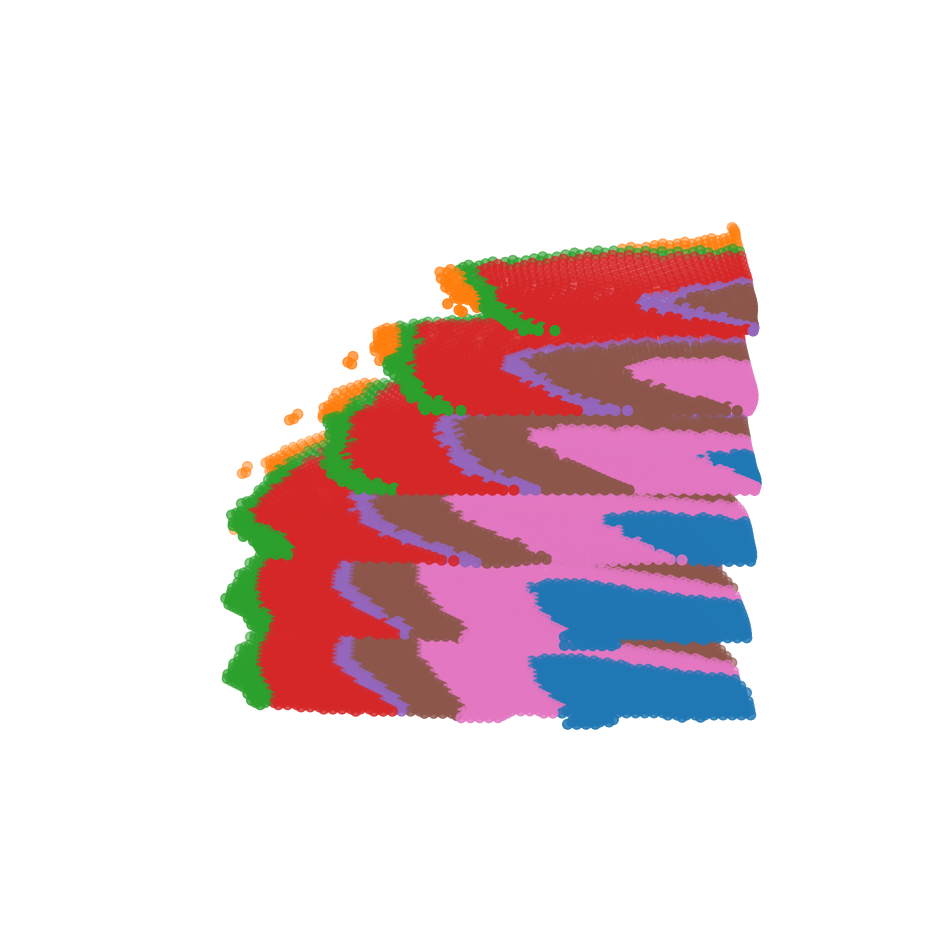

In [4]:
fig = plot_3d(coords.values, val=None, color=df['celltype_colors'], elev=15, azim=90, roll=0, frameon=False, show=True, s=50, save_dpi=300, return_fig=True) # Scube is from SPACEL

fig.savefig('STalign_gtAndScube_simuData_3dviz_angle15_90_100_s=50.pdf', bbox_inches="tight")